In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from scipy.cluster.hierarchy import dendrogram, linkage



In [5]:
df = pd.read_csv("store.csv")
print("Dataset loaded Succesfully")
print("Shape of dataset :",df.shape)
df.head()

Dataset loaded Succesfully
Shape of dataset : (10000, 5)


,reps,product,qty,revenue,region
0,Chitra,Galaxy,2,155.10,West
1,Vijay,Jet,2,39.30,North
2,Mala,Beacon,3,74.25,West
3,Suman,Alpen,3,100.98,North
4,Rachna,Orbit,2,44.98,North


In [6]:
print("Number of rows :",df.shape[0])
print("Number of columns :",df.shape[1])
print("\nColumn names\n")
print(df.columns)
print("\nData Types\n")
print(df.dtypes)

Number of rows : 10000
Number of columns : 5

Column names

Index(['reps', 'product', 'qty', 'revenue', 'region'], dtype='str')

Data Types

reps           str
product        str
qty          int64
revenue    float64
region         str
dtype: object


In [7]:
print("Missing Values in each columns: ")
print(df.isnull().sum())

Missing Values in each columns: 
reps       0
product    0
qty        0
revenue    0
region     0
dtype: int64


In [8]:
print("Stastical Summary")
df.describe()

Stastical Summary


,qty,revenue
count,10000.000000,10000.000000
mean,3.387400,90.570221
std,4.318308,127.803928
min,1.000000,18.430000
25%,2.000000,39.300000
50%,2.000000,58.425000
75%,3.000000,75.000000
max,25.000000,1998.750000


In [9]:
print("Unique values in categorical columns: ")
print("\nReps:")
print(df["reps"].unique())
print("\nProduct:")
print(df["product"].unique())
print("\nRegion:")
print(df["region"].unique())

Unique values in categorical columns: 

Reps:
<ArrowStringArray>
[ 'Chitra',   'Vijay',    'Mala',   'Suman',  'Rachna',    'Aash',   'Chand',
   'Suraj',    'Bala',    'Seet',    'Ravi',  'Anusha',  'Ananya',   'Jaggi',
    'Reva',   'Meena',     'Sai',   'Rahul',     'Ram',  'Prarth',   'Pooja',
   'Rishi',   'Ranga',    'Sesh', 'Shaanth', 'Bharath',   'Susan',   'Ratna',
  'Easwar',  'Prasad',   'Madhu',  'Suresh',  'Anahit',  'Sumedh',   'Manju',
 'Nandini', 'Santosh',  'Satyen',  'Vaghya',   'Palak',  'Aparna', 'Jagdish',
    'Vish',   'Kumar',    'John',    'Bhat', 'Hussain',    'Alka',  'Rohini',
  'Keshab',   'Nidhi',   'Satya',  'Venkat',  'Veeyes',   'Rajat', 'Chandra',
   'Kamat',    'Raji',   'Swami',     'Jay',  'Mukund',   'Priya',  'Kishen',
   'Vidya',   'Akila',   'Durga',     'Mak',   'Mehta',   'Javed',   'Sruti',
  'Mukesh', 'Kishore']
Length: 72, dtype: str

Product:
<ArrowStringArray>
[ 'Galaxy',     'Jet',  'Beacon',   'Alpen',   'Orbit', 'Trident',    'Mars',
  

<h2>4.Data Cleaning and Feature Selection</h2>

The clustering features are `qty`, `revenue`, `reps`, `product` and `region`. Missing numeric values are filled with the median and missing categorical values with the most frequent value. Duplicate rows are checked and removed.

In [10]:
# Work on a copy so the raw dataframe remains available for reference
df = df.copy()

print("Duplicate rows before cleaning:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

numerical_features = ["qty", "revenue"]
categorical_features = ["reps", "product", "region"]
required_features = numerical_features + categorical_features

missing_columns = [col for col in required_features if col not in df.columns]
if missing_columns:
    raise ValueError(f"Expected columns not found in store.csv: {missing_columns}")

print("Missing values before imputation:")
display(df[required_features].isnull().sum())

# Impute missing values with a simple, documented strategy
for col in numerical_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

for col in categorical_features:
    if df[col].isnull().any():
        mode_values = df[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

print("Missing values after imputation:")
display(df[required_features].isnull().sum())
print("Cleaned dataset shape:", df.shape)

Duplicate rows before cleaning: 3252
Shape after removing duplicates: (6748, 5)
Missing values before imputation:


qty        0
revenue    0
reps       0
product    0
region     0
dtype: int64

Missing values after imputation:


qty        0
revenue    0
reps       0
product    0
region     0
dtype: int64

Cleaned dataset shape: (6748, 5)


<h2>5.Prepeocessing </h2>

Numerical features are standardised so that `revenue` does not dominate `qty` in the distance calculations. Categorical features are one-hot encoded because the clustering algorithms need numeric input.
Since clustering has no target variable and no train/test split, the transformer is fitted on the cleaned data used for clustering.

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

X = preprocessor.fit_transform(df[required_features])
print("Preprocessing completed")
print("Shape of preprocessed data:", X.shape)

Preprocessing completed
Shape of preprocessed data: (6748, 90)


<h2>6.K-Means Clustering(Using Elbow Method)</h2>

K-Means is fitted for different values of k and inertia is recorderd.The Elbow curve helps to find the point after which adding more clusters gives only a small reduction in inertia

In [16]:
inertia = []
k_values = range(2, min(11, X.shape[0]))

for cluster_count in k_values:
    model = KMeans(n_clusters=cluster_count, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

print("Candidate k values:", list(k_values))
print("Inertia values:", inertia)

Candidate k values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values: [20537.70111422897, 18556.438304784297, 16987.672074564794, 15869.186246535568, 14993.414213692568, 14380.142039603406, 14192.721252425054, 13909.43669812467, 13674.825244588263]


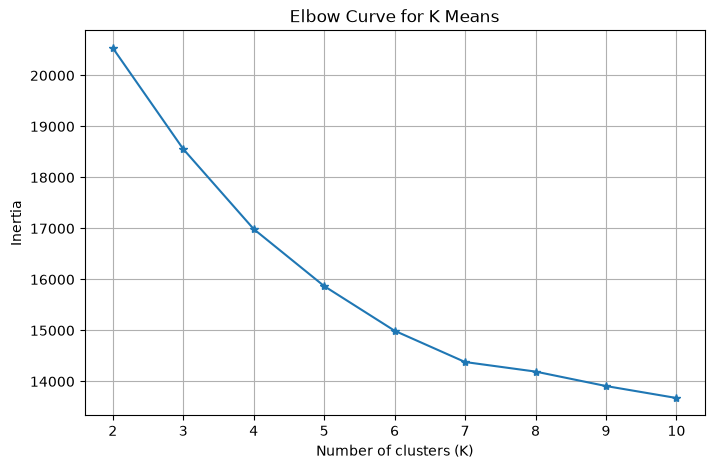

In [17]:
plt.figure(figsize=(8,5))
plt.plot(k_values,inertia,marker="*")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Curve for K Means")
plt.grid(True)
plt.show()


The Elbow curve shows the inertia decreasing as the number of clusters increases.The decrease is large for small values of k and becomes smaller after around k=6,So k=6 is selected as a reasonable number of clusters. The bend is gradual and not very sharp,which suggests that the clusters are not strongly seperated.

<h2>Fit K-means and evaluate the clusters </h2>

K-Means is fitted with the selected value of k=6 and the cluster labels are obtained.
The Silhouette score,Davies-Bouldin Index and Calinski-Harabasz Index  are then calculated from  cluster assignments

In [20]:
# Update k after examining the Elbow curve
k = min(6, X.shape[0] - 1)
if k < 2:
    raise ValueError("At least three rows are required for clustering evaluation.")

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

print("K-Means clustering completed")
print("Number of clusters (k):", k)
print("First 20 cluster labels:", kmeans_labels[:20])

K-Means clustering completed
Number of clusters (k): 6
First 20 cluster labels: [5 2 5 2 2 3 2 5 2 5 1 2 3 5 1 2 2 0 5 1]


In [21]:
unique,counts = np.unique(kmeans_labels,return_counts=True)
print("K-Means Cluster Distribution:")
for cluster,count in zip(unique,counts):
    print("Cluster",cluster,":",count)

K-Means Cluster Distribution:
Cluster 0 : 404
Cluster 1 : 988
Cluster 2 : 2096
Cluster 3 : 1019
Cluster 4 : 381
Cluster 5 : 1860


In [22]:
kmeans_silhouette = silhouette_score(X,kmeans_labels)
print("K-Means Silhoutte Score",kmeans_silhouette)

K-Means Silhoutte Score 0.19403706807712273


In [24]:
kmeans_db = davies_bouldin_score(X.toarray(),kmeans_labels)
print("K-Means Davies Bouldin Index:",kmeans_db)

K-Means Davies Bouldin Index: 1.8238442712146803


In [27]:
kmeans_ch = calinski_harabasz_score(X.toarray(), kmeans_labels)
print("K-Means Calinski-Harabasz Index:", kmeans_ch)

K-Means Calinski-Harabasz Index: 1450.2857507133401


print("---------------------------K-MEANS RESULTS ----------------------")

print("Silhouette Score       :", kmeans_silhouette)
print("Davies-Bouldin Index   :", kmeans_db)
print("Calinski-Harabasz Index:", kmeans_ch)


The Silhouette Score ranges from -1 to 1 and a higher value is better. A value close to 0 means that the clusters overlap, and a value around 0.2 indicates weak to moderate separation.

The Davies-Bouldin Index is better when it is lower. Values above 1 indicate that the clusters are close to each other.

The Calinski-Harabasz Index is better when it is higher. It has no upper limit, so it is mainly useful for comparing the models on the same data.

<h2>7.Aggolomerative Hierarchical Clustering (Using dendogram)</h2>

<h3>Dendogram:</h3>
The Dendogram shows how the observations are merged as the linkage distance increases.A random sample of 300 points is used for plot because drawing 10000 points would be slow and unreadable.

In [32]:
# Select a reproducible sample for dendrogram visualisation
sample_size = min(300, X.shape[0])
rng = np.random.default_rng(42)
sample_indices = rng.choice(X.shape[0], size=sample_size, replace=False)
X_sample = X[sample_indices]
print("Dendrogram sample shape:", X_sample.shape)

Dendrogram sample shape: (300, 90)


In [33]:
linked = linkage(
    X_sample,
    method="ward"
)
plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.title("Dendrogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

ValueError: setting an array element with a sequence.